## Упражнение

- Посмотрите на данные датчика, который отслеживает атмосферный CO2 из непрерывных проб воздуха в обсерватории Мауна-Лоа на Гавайях. Эти данные включают пробы CO2 с марта 1958 года по декабрь 1980 года.

In [2]:
import sys

if 'google.colab' in sys.modules:
  !pip install -U -qq tsa-course pmdarima

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.1/689.1 kB 13.0 MB/s eta 0:00:00


In [3]:
import warnings
warnings.filterwarnings("ignore")
from statsmodels.tools.sm_exceptions import ConvergenceWarning, ValueWarning
warnings.simplefilter('ignore', ConvergenceWarning)
warnings.simplefilter('ignore', ValueWarning)
warnings.simplefilter('ignore', UserWarning)
import time
from itertools import product
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels as ss
import seaborn as sns
from tqdm.notebook import tqdm
from scipy import stats
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import month_plot, plot_acf, plot_pacf
from statsmodels.graphics.gofplots import qqplot
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.tsa.seasonal import STL, seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tools.eval_measures import mse
from statsmodels.tsa.statespace.tools import diff
import pmdarima as pm
from tsa_course.lecture1 import fft_analysis
np.random.seed(0)

In [4]:
co2 = pd.read_csv('https://zenodo.org/records/10951538/files/arima_co2.csv?download=1',
                  header = 0,
                  names = ['idx', 'co2'],
                  skipfooter = 2)

co2['idx'] = pd.to_datetime(co2['idx'])
co2.set_index('idx', inplace=True)

co2.index.name = None
co2

,co2
1965-01-01,319.32
1965-02-01,320.36
1965-03-01,320.82
1965-04-01,322.06
1965-05-01,322.17
...,...
1980-08-01,337.19
1980-09-01,335.49
1980-10-01,336.63
1980-11-01,337.74


- Определите наличие основного тренда и сезонности в данных.
- Определите, являются ли данные стационарными.
- Разделите данные на обучающие (90%) и тестовые (10%).
- Найдите набор моделей-кандидатов SARIMAX, посмотрев на ACF и PACF.
- Выполните поиск по сетке для моделей-кандидатов.
- Выберите лучшие модели на основе показателей производительности, сложности модели и нормальности остатков.
- Сравните лучшую найденную вами модель с моделью из autoarima.

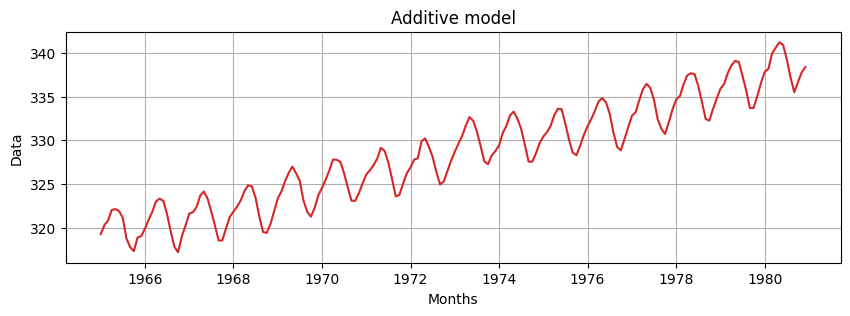

In [5]:
fig, ax = plt.subplots(1, 1, figsize=(10, 3))
ax.plot(co2.index, co2, color='tab:red')
ax.set_xlabel("Months")
ax.set_ylabel("Data")
plt.title("Additive model");
plt.grid()

Модель похожа на аддитивную, присутствует тренд и сезонность с постоянной амплитудой.

In [6]:
from scipy.fft import fft

def fft_analysis(signal):
  slope, intercept = np.polyfit(np.arange(len(signal)), signal, 1)
  trend = np.arange(len(signal)) * slope + intercept
  detrended = signal - trend
  fft_values = fft(detrended)
  frequencies = np.fft.fftfreq(len(fft_values))
  positive_frequencies = frequencies[frequencies > 0]
  magnitudes = np.abs(fft_values)[frequencies > 0]
  dominant_frequency = positive_frequencies[np.argmax(magnitudes)]
  print(f"Dominant Frequency: {dominant_frequency:.3f}")
  dominant_period = 1 / dominant_frequency
  print(f"Dominant Period: {dominant_period:.2f} time units")
  return dominant_period, positive_frequencies, magnitudes

period, _, _ =fft_analysis(co2['co2'])
print(f"Period: {np.round(period)}")

Dominant Frequency: 0.083
Dominant Period: 12.00 time units
Period: 12.0


In [7]:
# метод вывода разложения ряда на компоненты
def seas_decomp_plots(original, decomposition):
  _, axes = plt.subplots(4, 1, sharex=True, sharey=False, figsize=(7, 5))
  axes[0].plot(original, label='Original')
  axes[0].legend(loc='upper left')
  axes[1].plot(decomposition.trend, label='Trend')
  axes[1].legend(loc='upper left')
  axes[2].plot(decomposition.seasonal, label='Seasonality')
  axes[2].legend(loc='upper left')
  axes[3].plot(decomposition.resid, label='Residuals')
  axes[3].legend(loc='upper left')
  plt.show()

In [8]:
# декомпозиция аддитивной модели
additive_decomposition_sea = seasonal_decompose(co2, model='additive', period=12)

Декомпозиция seasonal_decompose:


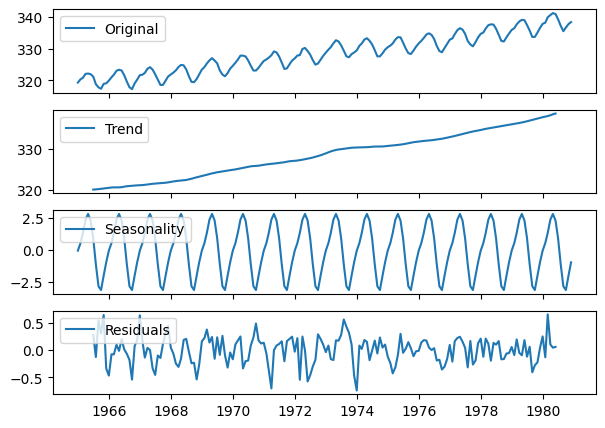

In [9]:
print("Декомпозиция seasonal_decompose:")
seas_decomp_plots(co2, additive_decomposition_sea)

Как и предполагалось, в данных есть тренд и сезонность.

In [10]:
# проверка стационарности: ADF-тест
adf_result = adfuller(co2)
print("Результаты ADF-теста на стационарность")
print(f"ADF-статистика: {adf_result[0]:.4f}")
print(f"p-value:       {adf_result[1]:.4f}")
print(f"Критические значения:")
for key, value in adf_result[4].items():
  print(f"   {key}: {value:.4f}")

# интерпретация
if adf_result[1] <= 0.05:
  print("\n→ Ряд СТАЦИОНАРЕН (нулевая гипотеза отвергнута)")
else:
  print("\n→ Ряд НЕСТАЦИОНАРЕН (нулевая гипотеза принимается)")

Результаты ADF-теста на стационарность
ADF-статистика: 1.2697
p-value:       0.9964
Критические значения:
   1%: -3.4674
   5%: -2.8778
   10%: -2.5755

→ Ряд НЕСТАЦИОНАРЕН (нулевая гипотеза принимается)


In [11]:
mytime = np.arange(len(co2))

# обучающий и тестовый наборы для smoothing_ts1
train_co2 = co2[:round(len(co2)*0.9)]
test_co2 = co2[round(len(co2)*0.9):]
mytime_train = mytime[:round(len(co2)*0.9)]
mytime_test = mytime[round(len(co2)*0.9):]

In [12]:
# сезонная дифференциация
train_co2_diff_12 = train_co2['co2'].diff(periods=12).dropna()

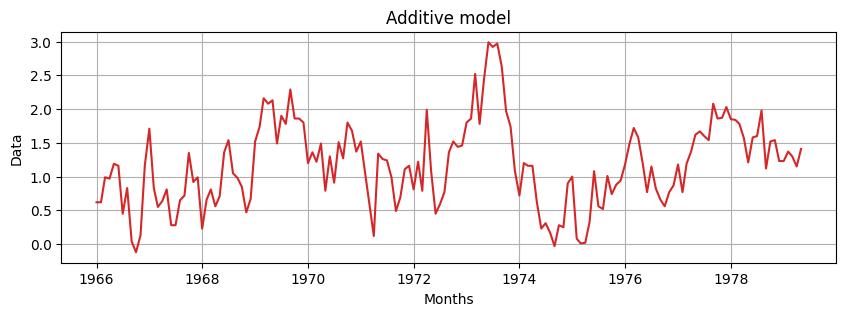

In [13]:
fig, ax = plt.subplots(1, 1, figsize=(10, 3))
ax.plot(train_co2_diff_12.index, train_co2_diff_12, color='tab:red')
ax.set_xlabel("Months")
ax.set_ylabel("Data")
plt.title("Additive model");
plt.grid()

In [14]:
# проверка стационарности: ADF-тест
adf_result = adfuller(train_co2_diff_12)
print("Результаты ADF-теста на стационарность")
print(f"ADF-статистика: {adf_result[0]:.4f}")
print(f"p-value:       {adf_result[1]:.4f}")
print(f"Критические значения:")
for key, value in adf_result[4].items():
  print(f"   {key}: {value:.4f}")

# интерпретация
if adf_result[1] <= 0.05:
  print("\n→ Ряд СТАЦИОНАРЕН (нулевая гипотеза отвергнута)")
else:
  print("\n→ Ряд НЕСТАЦИОНАРЕН (нулевая гипотеза принимается)")

Результаты ADF-теста на стационарность
ADF-статистика: -2.9492
p-value:       0.0399
Критические значения:
   1%: -3.4760
   5%: -2.8815
   10%: -2.5774

→ Ряд СТАЦИОНАРЕН (нулевая гипотеза отвергнута)


Продифференцированный ряд получился стационарным, поэтому d=0 (т.к. не применяли дифференциацию тренда), D=1 (т.к. применили сезонную дифференциацию один раз).

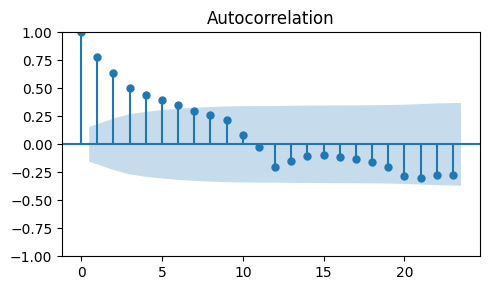

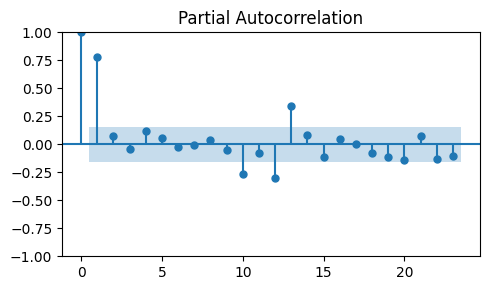

In [15]:
_, ax = plt.subplots(1, 1, figsize=(5, 3))
plot_acf(train_co2_diff_12, ax=ax)
plt.tight_layout();

_, ax = plt.subplots(1, 1, figsize=(5, 3))
plot_pacf(train_co2_diff_12, ax=ax)
plt.tight_layout();

После сезонного дифференцирования наблюдается плавное затухание на ACF и резкий спад на PACF, что указывает на авторегрессионную модель порядка p=1. На сезонных лагах значения у ACF не значимы, а у PACF значимы, что указывает на авторегрессионную модель порядка P=1. Будет построена модель SARIMA(1,0,0)(1,1,0,12).

In [16]:
sar = ss.tsa.statespace.sarimax.SARIMAX(train_co2['co2'],
                                order=(1,0,0),
                                seasonal_order=(1,1,0,12),
                                trend='t').fit(disp=False)
sar.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                      
==========================================================================================
Dep. Variable:                                co2   No. Observations:                  173
Model:             SARIMAX(1, 0, 0)x(1, 1, 0, 12)   Log Likelihood                 -56.306
Date:                            Fri, 17 Apr 2026   AIC                            120.612
Time:                                    14:37:39   BIC                            132.937
Sample:                                01-01-1965   HQIC                           125.616
                                     - 05-01-1979                                         
Covariance Type:                              opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
drift          0.0012      0.001      1.878      0.060   -5.05e-05       0.002
ar.L1          0.9314      0.031     30.459      0.000       0.871       0.991
ar.S.L12      -0.5334      0.069     -7.741      0.000      -0.668      -0.398
sigma2         0.1127      0.014      8.240      0.000       0.086       0.140
===================================================================================
Ljung-Box (L1) (Q):                   3.01   Jarque-Bera (JB):                 0.50
Prob(Q):                              0.08   Prob(JB):                         0.78
Heteroskedasticity (H):               0.47   Skew:                             0.07
Prob(H) (two-sided):                  0.01   Kurtosis:                         2.76
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

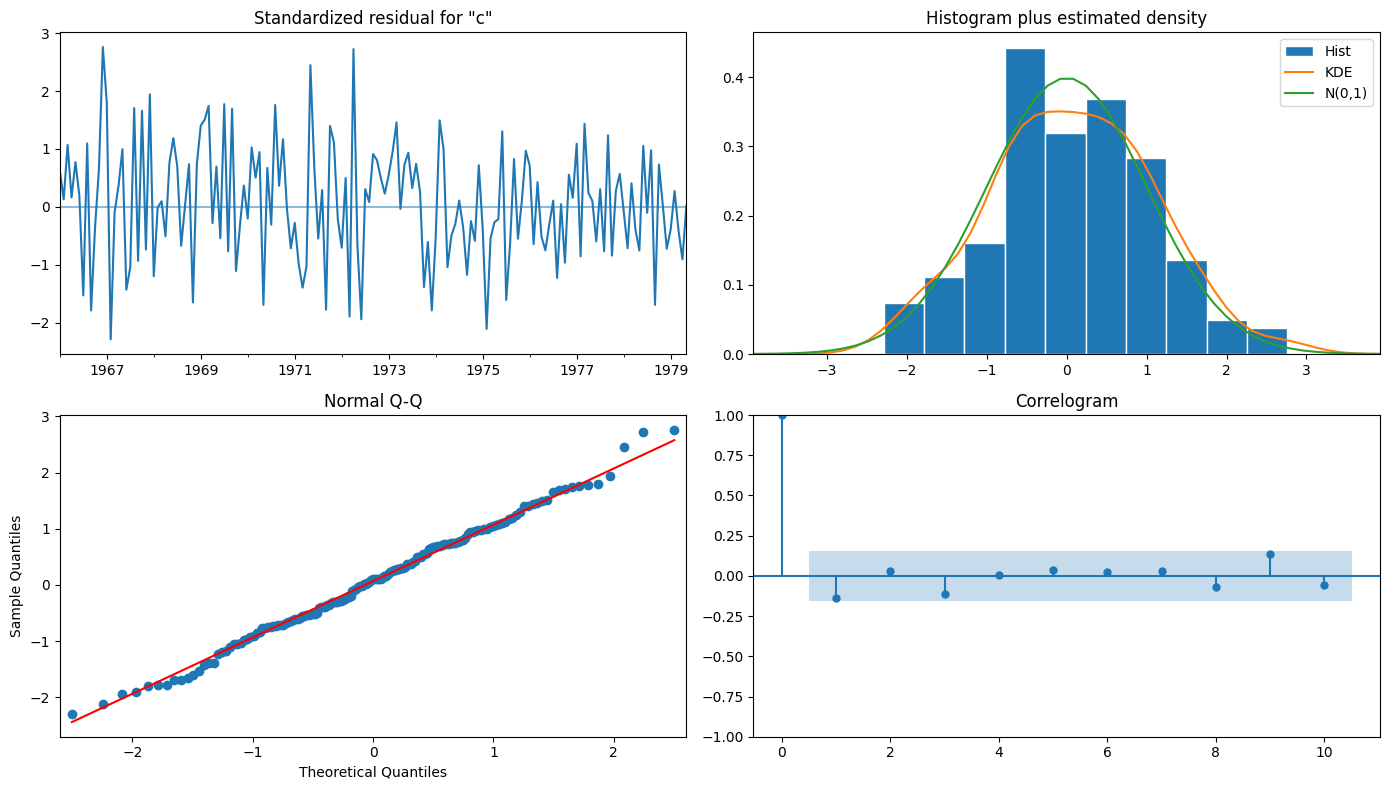

In [17]:
sar.plot_diagnostics(figsize=(14, 8))
plt.tight_layout();

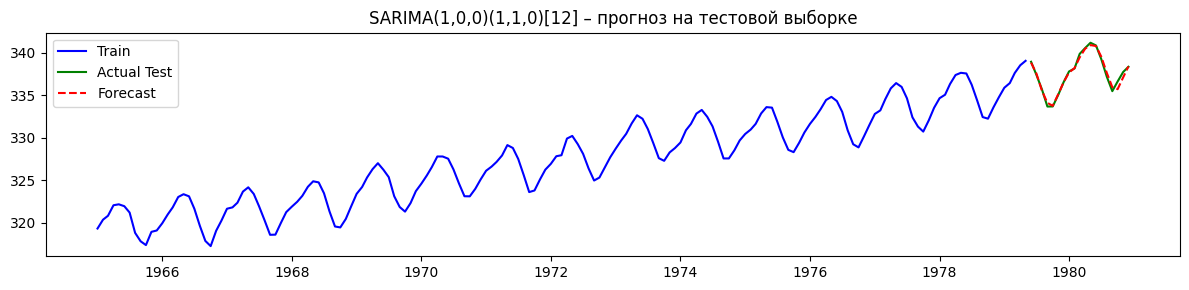

MSE: 0.12


In [18]:
test_co2_pred = sar.predict(start=round(len(co2)*0.9), end=len(co2)-1, dynamic=False)

# график: реальные данные + прогноз на тесте
plt.figure(figsize=(12, 3))
plt.plot(train_co2.index, train_co2, label='Train', color='blue')
plt.plot(test_co2.index, test_co2, label='Actual Test', color='green')
plt.plot(test_co2.index, test_co2_pred, label='Forecast', color='red', linestyle='--')
plt.legend()
plt.title('SARIMA(1,0,0)(1,1,0)[12] – прогноз на тестовой выборке')
plt.tight_layout()
plt.show()

# MSE на тесте
from sklearn.metrics import mean_squared_error
mse_val = mean_squared_error(test_co2, test_co2_pred)
print(f"MSE: {mse_val:.2f}")

Ошибка MSE довольна мала, и предсказания хорошо повторяют тестовые данные. Модель подобрана верно.

In [19]:
model = pm.auto_arima(train_co2,
                      start_p=0, start_q=0,
                      test='adf',
                      max_p=2, max_q=2,
                      m=12,
                      start_P=0, start_Q=0,
                      max_P=2, max_Q=2,
                      seasonal=True,
                      d=None,
                      D=1,
                      trace=True,
                      error_action='ignore',
                      suppress_warnings=True,
                      stepwise=True)

Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,1,0)[12]             : AIC=170.597, Time=0.07 sec
 ARIMA(1,1,0)(1,1,0)[12]             : AIC=116.562, Time=0.36 sec
 ARIMA(0,1,1)(0,1,1)[12]             : AIC=inf, Time=2.46 sec
 ARIMA(1,1,0)(0,1,0)[12]             : AIC=167.617, Time=0.05 sec
 ARIMA(1,1,0)(2,1,0)[12]             : AIC=111.881, Time=1.03 sec
 ARIMA(1,1,0)(2,1,1)[12]             : AIC=inf, Time=5.59 sec
 ARIMA(1,1,0)(1,1,1)[12]             : AIC=inf, Time=0.68 sec
 ARIMA(0,1,0)(2,1,0)[12]             : AIC=116.549, Time=0.19 sec
 ARIMA(2,1,0)(2,1,0)[12]             : AIC=113.711, Time=0.40 sec
 ARIMA(1,1,1)(2,1,0)[12]             : AIC=111.441, Time=0.49 sec
 ARIMA(1,1,1)(1,1,0)[12]             : AIC=115.866, Time=0.18 sec
 ARIMA(1,1,1)(2,1,1)[12]             : AIC=inf, Time=1.62 sec
 ARIMA(1,1,1)(1,1,1)[12]             : AIC=inf, Time=0.83 sec
 ARIMA(0,1,1)(2,1,0)[12]             : AIC=111.241, Time=0.26 sec
 ARIMA(0,1,1)(1,1,0)[12]             : AIC=116.164, T

                                      SARIMAX Results                                      
Dep. Variable:                                   y   No. Observations:                  173
Model:             SARIMAX(0, 1, 1)x(2, 1, [], 12)   Log Likelihood                 -51.621
Date:                             Fri, 17 Apr 2026   AIC                            111.241
Time:                                     14:38:00   BIC                            123.542
Sample:                                 01-01-1965   HQIC                           116.236
                                      - 05-01-1979                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.2331      0.069     -3.376      0.001      -0.368      -0.098
ar.S.L12      -0.6803      

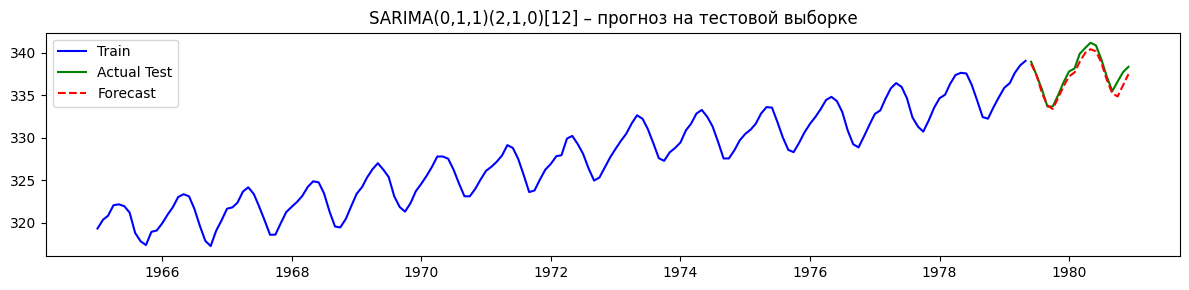

MSE: 0.53


In [20]:
print(model.summary())

test_co2_pred = model.predict(n_periods=len(test_co2))

# график: реальные данные + прогноз на тесте
plt.figure(figsize=(12, 3))
plt.plot(train_co2.index, train_co2, label='Train', color='blue')
plt.plot(test_co2.index, test_co2, label='Actual Test', color='green')
plt.plot(test_co2.index, test_co2_pred, label='Forecast', color='red', linestyle='--')
plt.legend()
plt.title('SARIMA(0,1,1)(2,1,0)[12] – прогноз на тестовой выборке')
plt.tight_layout()
plt.show()

# MSE на тесте
from sklearn.metrics import mean_squared_error
mse_val = mean_squared_error(test_co2, test_co2_pred)
print(f"MSE: {mse_val:.2f}")

AutoARIMA подобрала оптимальный набор: ARIMA(0,1,1)(2,1,0)[12]. Параметры AutoARIMA сильно отличаются от подобранных параметров в SARIMA. Ошибка MSE в AutoARIMA больше, т.е. прогноз рассчитался хуже.